# Exercises week 43: reading a classifier — the confusion matrix, the ROC curve and the threshold

**FYS-STK3155/4155 Applied Data Analysis and Machine Learning**

**October 19–23, 2026**

**Deadline: Friday October 23 at midnight** (one notebook per group, in
Canvas).

## Aims of this week's exercises

Project 2 asks you to train classifiers — logistic regression as the
baseline and a neural network with hidden layers — and then to *say what
they do*: the confusion matrix on the test set, with its interpretation.
This week you build the tools for that, implementing them yourself from the
definitions and checking them against `scikit-learn`:

- the confusion matrix and the quantities read off its four counts —
  accuracy, precision, recall, $F_1$ (Section 5.12, Eqs. 5.67–5.70);
- the ROC curve and the area under it, the AUC, and why they measure
  something a single threshold cannot;
- (optional) the $K\times K$ confusion matrix of a multiclass classifier and
  how to read a $2\times2$ matrix off it.

The Monday lecture went through what every one of these measures *means* on
a worked screening example and then applied them to "is it a five?" on the
full MNIST set (`week43monday.pdf`, `week43monday.ipynb`); the Tuesday session
goes through the worked example in detail and then writes the same code on
the small digits set (`week43tuesday.ipynb`). The classifiers can be your
own Project 2 code (recommended: this is the code you will report on) or
`scikit-learn`'s `LogisticRegression` and `MLPClassifier`.

There is no validation set and no cross-validation in this week's
exercises: how to cross-validate your Project 2 network is the topic of next
week's Tuesday session and exercises.

**Reading:** Sections 5.12–5.13 of the lecture notes; Eq. (2.24) for the
standard error of a proportion. Hastie, Tibshirani and Friedman, Section
9.2.5; Raschka et al., Chapter 6 ("Looking at different performance
evaluation metrics").

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import metrics as skm
np.random.seed(2026)

## Exercise 1: your own confusion matrix, ROC curve and AUC, checked

Implement the following functions from their definitions. Labels are in
$\{0,1\}$ with $1$ the positive class; `scores` are the output probabilities
(or any monotone score) of a classifier.

**a)** `confusion_matrix(y_true, y_pred)` returning the four counts
`tp, fn, fp, tn` of Eq. (5.67), and from them the accuracy, precision,
recall and $F_1$ of Eqs. (5.68)–(5.70) (handle the cases where a
denominator is zero).

**b)** `roc_curve(y_true, scores)` returning the false positive rates, true
positive rates and thresholds for every distinct score, from **one sorted
pass**: sort by decreasing score and walk down the list — every sample
flagged adds one to TP if it is a positive and one to FP if it is a
negative; then `auc_trapezoid(fpr, tpr)` for the area.

**c)** `roc_auc(y_true, scores)` by the rank formula of the lecture,
$\mathrm{AUC}=\bigl(\sum_{i\in\mathrm{pos}}R_i-\tfrac12 n_+(n_++1)\bigr)/(n_+n_-)$,
with average ranks for tied scores (`np.unique` with `return_inverse` and
`return_counts`, or `scipy.stats.rankdata`). Explain in one sentence why
this is the probability that a random positive outscores a random negative.

**d)** Test everything on the small example below against `sklearn.metrics`
(`confusion_matrix`, `precision_score`, `recall_score`, `f1_score`,
`roc_curve` with `drop_intermediate=False`, `roc_auc_score`). Mind the
layout of `sklearn.metrics.confusion_matrix`: rows true $0/1$, columns
predicted $0/1$, so `[[TN, FP], [FN, TP]]`. The example has tied scores on
purpose: the three AUCs must still agree.

Regarding roc_auc(y_true, scores), the reason this is the probability that a random positive outscores a random negative is that the equation finds how many of randomly chosen pairs of labels with 1 negative and 1 positive has a higher positive label-score, and then divides this by the number of pairs. This then becomes the probability that a random positive have a higher score than a random negative.

In [2]:
def confusion_matrix(y_true, y_pred):
    """
    Counts TP, FN, FP and TN from the true labels (1 is really positive, an 0 is really negative) and the yes/no predictions (score > 0.5 threshold). 
    classification_report then computes accuracy, precision, recall and F1 from those four counts.
    """
    y_true, y_pred = np.asarray(y_true).astype(int), np.asarray(y_pred).astype(int)
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    return tp, fn, fp, tn

def classification_report(y_true, y_pred):
    """Accuracy, precision, recall and F1 from the four counts"""
    tp, fn, fp, tn = confusion_matrix(y_true, y_pred)
    n = tp + fn + fp + tn
    accuracy = (tp + tn) / n
    precision = tp / (tp + fp) if tp + fp else 0.0          # of those flagged positive, how many were?
    recall = tp / (tp + fn) if tp + fn else 0.0             # of the positives, how many did we find? (= TPR)
    specificity = tn / (tn + fp) if tn + fp else 0.0        # of the negatives, how many did we leave alone? (= 1 - FPR)
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    balanced = 0.5 * (recall + specificity)
    denom = np.sqrt(float(tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    mcc = ((tp * tn - fp * fn) / denom) if denom else 0.0  # Matthews correlation coefficient: correlation of y and y_hat
    return dict(TP=tp, FN=fn, FP=fp, TN=tn, accuracy=accuracy, precision=precision, recall=recall,
                specificity=specificity, f1=f1, balanced_accuracy=balanced, mcc=mcc)

def roc_curve(y_true, scores):
    """ 
    Sorts the samples by score, from highest to lowest, and lowers the threshold one step at a time. 
    At each step it records the TPR (fraction of positives found) and the FPR (fraction of negatives falsely flagged). 
    auc_trapezoid then computes the area under that curve.
    """
    y_true, scores = np.asarray(y_true).astype(int), np.asarray(scores, dtype=float)
    order = np.argsort(-scores, kind="mergesort")
    y, s = y_true[order], scores[order]
    tp, fp = np.cumsum(y == 1), np.cumsum(y == 0)
    last = np.r_[np.diff(s) != 0, True]            # one point per distinct threshold
    tpr = np.r_[0.0, tp[last] / max(tp[-1], 1)]
    fpr = np.r_[0.0, fp[last] / max(fp[-1], 1)]
    thresholds = np.r_[np.inf, s[last]]
    return fpr, tpr, thresholds

def auc_trapezoid(fpr, tpr):
    """The area under the ROC curve by the trapezoidal rule."""
    return float(np.sum(np.diff(fpr) * (tpr[1:] + tpr[:-1]) / 2))

def roc_auc(y_true, scores):
    """The AUC as the probability that a random positive outranks a random negative (Section 5.12), from the ranks.
    - Count the pairs where the positive has the higher score, and divide by the total number of pairs. 
    This is just a different method of computing the AUC and should give the same value as calculating the area under the graph 
    by the trapezoid.
    """
    y_true, scores = np.asarray(y_true).astype(int), np.asarray(scores, dtype=float)
    _, inv, cnt = np.unique(scores, return_inverse=True, return_counts=True)
    first = np.cumsum(cnt) - cnt + 1                  # rank of the first member of each tie group
    ranks = (first + (cnt - 1) / 2)[inv]              # average rank within the group
    n_pos = int(np.sum(y_true == 1))
    n_neg = len(y_true) - n_pos
    S = np.sum(ranks[y_true == 1]) - n_pos * (n_pos + 1) / 2
    return float(S / (n_pos * n_neg))


# a small test: 20 samples, 6 positives, scores rounded to one decimal so that there are ties
rng = np.random.default_rng(2)
y_small = np.array([1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0])
s_small = np.round(np.clip(0.35 * y_small + rng.normal(0.3, 0.2, 20), 0, 1), 1)
print(confusion_matrix(y_small, s_small > 0.5), skm.confusion_matrix(y_small, s_small > 0.5))
print(roc_auc(y_small, s_small), auc_trapezoid(*roc_curve(y_small, s_small)[:2]), skm.roc_auc_score(y_small, s_small))

(5, 1, 1, 13) [[13  1]
 [ 1  5]]
0.8571428571428571 0.8571428571428572 0.8571428571428571


We see that the confusion matrix gives the same outputs as calculating it with scikit, only rearranged as such:
confusion matrix function: (5 TP, 1 FN, 1 FP, 13 TN)
scikit:
[[    TN = 13       FP = 1  ]
[    FN = 1        TP = 5  ]]

The AUC computed three ways, roc_auc, roc_trapezoid and scikit, also gives the same output (only change in the last decimal)

**The same with `scikit-learn`.** Once your functions agree with the
library, this is the template you can use in Project 2 for the test set
(`y_test` the true labels, `p_test` the output probabilities of your
classifier, `y_pred = p_test > 0.5` the decisions):

[[13  1]
 [ 1  5]]
accuracy 0.9000  precision 0.8333  recall 0.8333  F1 0.8333
              precision    recall  f1-score   support

    negative       0.93      0.93      0.93        14
    positive       0.83      0.83      0.83         6

    accuracy                           0.90        20
   macro avg       0.88      0.88      0.88        20
weighted avg       0.90      0.90      0.90        20

AUC 0.8571


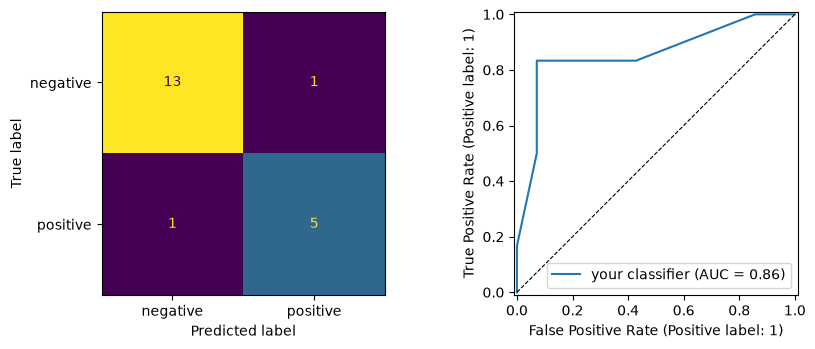

In [3]:
from sklearn.metrics import (confusion_matrix as sk_confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, precision_score, recall_score, f1_score,
                             classification_report as sk_classification_report,
                             roc_curve as sk_roc_curve, roc_auc_score, RocCurveDisplay)

y_test, p_test = y_small, s_small          # replace by your test labels and output probabilities
y_pred = p_test > 0.5

cm = sk_confusion_matrix(y_test, y_pred)   # [[TN, FP], [FN, TP]]
print(cm)
print(f"accuracy {accuracy_score(y_test, y_pred):.4f}  precision {precision_score(y_test, y_pred, zero_division=0):.4f}  "
      f"recall {recall_score(y_test, y_pred):.4f}  F1 {f1_score(y_test, y_pred):.4f}")
print(sk_classification_report(y_test, y_pred, target_names=["negative", "positive"], zero_division=0))

fpr, tpr, thresholds = sk_roc_curve(y_test, p_test, drop_intermediate=False)
print(f"AUC {roc_auc_score(y_test, p_test):.4f}")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
ConfusionMatrixDisplay(cm, display_labels=["negative", "positive"]).plot(ax=ax[0], colorbar=False)
RocCurveDisplay.from_predictions(y_test, p_test, ax=ax[1], name="your classifier")
ax[1].plot([0, 1], [0, 1], "k--", lw=0.8)
plt.tight_layout(); plt.show()

## Exercise 2: MNIST, one digit against the rest

This is the Monday lecture's example on data of your choosing, with your
Project 2 code. Use the full MNIST set as described in Project 2 (the file
`mnist.npz`, 60 000 training and 10 000 test images, flattened and scaled to
$[0,1]$); if your laptop is slow, train on a subset of the training images
but evaluate on the full test set.

**a)** Pick a digit $d$ (the lecture used $5$; choose a different one) and
set $y=1$ for the images of $d$. Report the prevalence of $d$ in the test set
and the accuracy of the majority rule ("never $d$") — the number every
accuracy below must be compared with.

**b)** Train logistic regression (no hidden layer, sigmoid output, cross
entropy) and a network with one hidden layer on the training set, with the
SGD of Project 2. On the test set, at threshold $0.5$, report for both the
confusion matrix in the layout of Eq. (5.67) and the accuracy, precision,
recall and $F_1$ from your own exercise-1 functions, checked against the
`scikit-learn` template. Say in two sentences what the matrices tell you
that the two accuracies do not, and what fraction of the remaining error
(relative to the majority rule) each classifier removed.

**c)** The ROC curves of both classifiers in one figure, with the AUC by
your trapezoidal rule, by your rank formula and by `roc_auc_score`, and the
point corresponding to $t=0.5$ marked on each curve. Add a histogram of the
output probabilities of the test images, separately for the two classes,
on a logarithmic vertical axis. Where do the errors live, and what does the
difference between the two AUCs say that the confusion matrices at $0.5$ do
not?

**d)** Standard errors: of the test accuracy and of the recall (Eq. 2.24,
$\sqrt{\hat p(1-\hat p)/n}$ with the appropriate $n$ in each case). Would
you call the difference between your two classifiers significant?

In [4]:
# your Project 2 network (or the week-41 code: create_layers, feed_forward, backpropagation, train, predict)

d = 7                               # your digit
data = np.load("mnist.npz")            # see Project 2 for where to get it
x_train = data["x_train"].reshape(len(data["x_train"]), -1) / 255.0
x_test = data["x_test"].reshape(len(data["x_test"]), -1) / 255.0
y_train = (data["y_train"] == d).astype(float)
y_test = (data["y_test"] == d).astype(float)


# a)
prevalence = y_test.mean()
majority_accuracy = 1 - y_test.mean()
print(f"prevalence of {d}: {prevalence:.4f}, majority rule accuracy: {majority_accuracy:.4f}")


prevalence of 7: 0.1028, majority rule accuracy: 0.8972


In [5]:
# b) 
# defining all the functions needed
# The network of weeks 41 and 42, copied from week43monday.ipynb

def sigmoid(z):
    """The logistic function, Eq. (8.22), evaluated without overflow."""
    e = np.exp(-np.abs(z))
    return np.where(z >= 0, 1.0 / (1.0 + e), e / (1.0 + e))


def sigmoid_prime(z):
    s = sigmoid(z)
    return s * (1.0 - s)


def relu(z):
    """Eq. (8.23)."""
    return np.maximum(0.0, z)


def relu_prime(z):
    return (z > 0).astype(float)


def identity(z):
    return z


def identity_prime(z):
    return np.ones_like(z)


def softmax(z):
    """Eq. (8.75) with the shift of Eq. (5.30): rows are samples, columns classes."""
    e = np.exp(z - np.max(z, axis=1, keepdims=True))
    return e / np.sum(e, axis=1, keepdims=True)


ACTIVATIONS = {"sigmoid": (sigmoid, sigmoid_prime),
               "relu": (relu, relu_prime),
               "identity": (identity, identity_prime)}

OUTPUT = {"mse": identity, "binary": sigmoid, "softmax": softmax}


def create_layers(sizes, hidden_activation="sigmoid", rng=None):
    """A list of (W, b) pairs, W of shape (inputs, outputs) as in the template.

    sizes = [784, 100, 10] gives two layers: 784 -> 100 -> 10.  The weights are
    drawn with the variance of Eq. (8.74) (He) for ReLU and 1/inputs otherwise,
    the biases are set to 0.01 as in the template.
    """
    rng = np.random.default_rng(2026) if rng is None else rng
    layers = []
    for n_in, n_out in zip(sizes[:-1], sizes[1:]):
        scale = np.sqrt(2.0 / n_in) if hidden_activation == "relu" else np.sqrt(1.0 / n_in)
        W = rng.normal(0.0, scale, (n_in, n_out))
        b = np.zeros(n_out) + 0.01
        layers.append((W, b))
    return layers


def feed_forward(X, layers, hidden_activation="sigmoid", head="mse"):
    """Eq. (8.21) layer by layer, samples in rows.

    Returns the lists z (pre-activations) and a (activations, a[0] = X): every
    one of them is needed on the way back, so the forward pass stores them.
    """
    f, _ = ACTIVATIONS[hidden_activation]
    a, z = [X], []
    for l, (W, b) in enumerate(layers):
        zl = a[-1] @ W + b                       # the template's  x @ w_1 + b_1
        z.append(zl)
        if l == len(layers) - 1:
            a.append(OUTPUT[head](zl))           # the output head
        else:
            a.append(f(zl))
    return z, a


def predict(X, layers, hidden_activation="sigmoid", head="mse"):
    """The output of the network: a vector of predictions, probabilities, or class probabilities."""
    return feed_forward(X, layers, hidden_activation, head)[1][-1]


def cost(X, Y, layers, hidden_activation="sigmoid", head="mse", lmbd2=0.0, lmbd1=0.0):
    """The cost of Eq. (8.31): data term for the chosen head plus L2 and L1 penalties on the weights."""
    out = predict(X, layers, hidden_activation, head)
    n = X.shape[0]
    if head == "mse":                            # Eq. (8.32)
        data = 0.5 * np.sum((out - Y) ** 2) / n
    elif head == "binary":                       # Eq. (5.13), averaged
        p = np.clip(out, 1e-12, 1 - 1e-12)
        data = -np.mean(Y * np.log(p) + (1 - Y) * np.log(1 - p))
    else:                                        # Eq. (5.28), averaged, one-hot Y
        p = np.clip(out, 1e-12, 1.0)
        data = -np.mean(np.sum(Y * np.log(p), axis=1))
    reg = sum(lmbd2 * np.sum(W ** 2) + lmbd1 * np.sum(np.abs(W)) for W, _ in layers)
    return data + reg


def backpropagation(X, Y, layers, hidden_activation="sigmoid", head="mse", lmbd2=0.0, lmbd1=0.0):
    """Eqs. (8.65)-(8.68) for all samples at once; returns a list of (dW, db) with the shapes of (W, b)."""
    _, fp = ACTIVATIONS[hidden_activation]
    n = X.shape[0]
    z, a = feed_forward(X, layers, hidden_activation, head)
    delta = (a[-1] - Y) / n                      # Eq. (8.69): the same line for all three heads
    grads = [None] * len(layers)
    for l in range(len(layers) - 1, -1, -1):
        W, _ = layers[l]
        dW = a[l].T @ delta                      # Eq. (8.68): outer products, summed over the samples
        dW += 2.0 * lmbd2 * W + lmbd1 * np.sign(W)   # the penalties of Section 8.12 (weights only)
        db = np.sum(delta, axis=0)               # Eq. (8.67)
        grads[l] = (dW, db)
        if l > 0:
            delta = (delta @ W.T) * fp(z[l - 1])     # Eq. (8.66): pull back through W, modulate by f'
    return grads


def accuracy(X, y, layers, hidden_activation, head):
    """Fraction of correct labels; y holds integer labels for softmax, 0/1 for binary."""
    out = predict(X, layers, hidden_activation, head)
    if head == "softmax":
        return np.mean(np.argmax(out, axis=1) == y)
    return np.mean((out[:, 0] > 0.5) == (y > 0.5))


def train(X, Y, layers, hidden_activation="sigmoid", head="mse", gamma=0.1, epochs=100,
          batch_size=None, lmbd2=0.0, lmbd1=0.0, rng=None, X_test=None, y_test=None, verbose=False):
    """Plain gradient descent, Eq. (8.70), on minibatches (batch_size=None: the whole set).

    Returns the trained layers and a history with the training cost after
    every epoch and, when a test set is given, the test accuracy.
    """
    rng = np.random.default_rng(2026) if rng is None else rng
    n = X.shape[0]
    M = n if batch_size is None else batch_size
    history = {"cost": [], "test_accuracy": []}
    for epoch in range(epochs):
        order = rng.permutation(n)
        for s in range(0, n, M):
            idx = order[s:s + M]
            grads = backpropagation(X[idx], Y[idx], layers, hidden_activation, head, lmbd2, lmbd1)
            layers = [(W - gamma * dW, b - gamma * db) for (W, b), (dW, db) in zip(layers, grads)]
        history["cost"].append(cost(X, Y, layers, hidden_activation, head, lmbd2, lmbd1))
        if X_test is not None:
            history["test_accuracy"].append(accuracy(X_test, y_test, layers, hidden_activation, head))
        if verbose:
            msg = f"epoch {epoch + 1:3d}: cost {history['cost'][-1]:.4f}"
            if X_test is not None:
                msg += f"  test accuracy {history['test_accuracy'][-1]:.4f}"
            print(msg)
    return layers, history

In [6]:
# b)

# logistic regression: 784 -> 1
layers_lr = create_layers([784, 1], "sigmoid", np.random.default_rng(2026))
layers_lr, hist_lr = train(x_train, y_train[:, None], layers_lr, "sigmoid", "binary",# train with SGD: 10 epochs, batches of 100, learning rate 0.1
                                                                                     # "binary" = output is the probability that the image is digit d
                           gamma=0.1, epochs=10, batch_size=100)
p_lr = predict(x_test, layers_lr, "sigmoid", "binary")[:, 0] # output probabilities for the 10 000 test images using logistic regression

# one hidden layer of 32 ReLU units: 784 -> 32 -> 1
layers_nn = create_layers([784, 32, 1], "relu", np.random.default_rng(2026))
layers_nn, hist_nn = train(x_train, y_train[:, None], layers_nn, "relu", "binary",
                           gamma=0.1, epochs=10, batch_size=100)
p_nn = predict(x_test, layers_nn, "relu", "binary")[:, 0] # output probabilities for the 10 000 test images using one hidden layer

In [7]:
# b)
# testing agains scikitlearn, using exercise 1 functions
for name, p in (("logistic regression", p_lr), ("one hidden layer", p_nn)): # running through all the calculated probabilites for each classifier
    r = classification_report(y_test, p > 0.5) # turns the probabilities into true/false (7 or no 7) at threshold 0.5
    print(f"--- {name}, t = 0.5")
    print(f"  TP {r['TP']}  FN {r['FN']}  FP {r['FP']}  TN {r['TN']}")
    print(f"  accuracy {r['accuracy']:.4f}  precision {r['precision']:.4f}  recall {r['recall']:.4f}  F1 {r['f1']:.4f}")
    print(f"  fraction of the remaining error removed: {1 - (1 - r['accuracy']) / y_test.mean():.3f}")
    print(f"  sklearn confusion_matrix:\n{skm.confusion_matrix(y_test, p > 0.5)}")
    print(f"  sklearn precision {skm.precision_score(y_test, p > 0.5):.4f}  recall {skm.recall_score(y_test, p > 0.5):.4f}  "
          f"F1 {skm.f1_score(y_test, p > 0.5):.4f}")

--- logistic regression, t = 0.5
  TP 926  FN 102  FP 46  TN 8926
  accuracy 0.9852  precision 0.9527  recall 0.9008  F1 0.9260
  fraction of the remaining error removed: 0.856
  sklearn confusion_matrix:
[[8926   46]
 [ 102  926]]
  sklearn precision 0.9527  recall 0.9008  F1 0.9260
--- one hidden layer, t = 0.5
  TP 979  FN 49  FP 33  TN 8939
  accuracy 0.9918  precision 0.9674  recall 0.9523  F1 0.9598
  fraction of the remaining error removed: 0.920
  sklearn confusion_matrix:
[[8939   33]
 [  49  979]]
  sklearn precision 0.9674  recall 0.9523  F1 0.9598


Both classifiers agree exactly with scikit-learn regarding entries in the confusion matrix, precision, recall and F1.

The two accuracies (98.5 % and 99.2 %) are almost the same and are both close to the 89.7 % of the majority rule, but the confusion matrices show which errors are made: 
logistic regression misses 102 of the 1028 sevens (recall 0.90) and makes 46 false alarms, 
while the network with one hidden layer misses only 49 (recall 0.95) and makes 33 false alarms, so it roughly halves the number of missed sevens.

Relative to the majority rule, logistic regression removes 86 % of the remaining error and the network removes 92 %.

logistic regression: AUC trapezoid 0.98940, ranks 0.98940, sklearn 0.98940; ROC curve: 10001 points, identical to sklearn's: True
one hidden layer: AUC trapezoid 0.99774, ranks 0.99774, sklearn 0.99774; ROC curve: 10001 points, identical to sklearn's: True


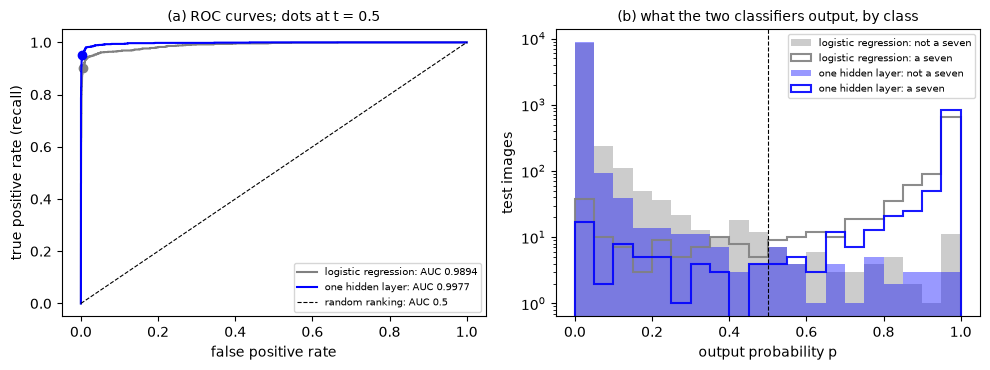

In [8]:
# c)

# from week43tuesday.ipynb, Step 4. Changed so that loop runs over probabilities and names seperately instead of using 'models' dictionary
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))

for name, p, col in (("logistic regression", p_lr, "grey"), ("one hidden layer", p_nn, "blue")): # giving each visualized classifier a color in plotting as well
    fpr, tpr, thr = roc_curve(y_test, p)
    auc_t, auc_r, auc_s = auc_trapezoid(fpr, tpr), roc_auc(y_test, p), skm.roc_auc_score(y_test, p)
    fpr_s, tpr_s, _ = skm.roc_curve(y_test, p, drop_intermediate=False)   # sklearn drops collinear points by default
    print(f"{name}: AUC trapezoid {auc_t:.5f}, ranks {auc_r:.5f}, sklearn {auc_s:.5f}; "
          f"ROC curve: {len(fpr)} points, identical to sklearn's: {np.allclose(fpr, fpr_s) and np.allclose(tpr, tpr_s)}")
    ax[0].plot(fpr, tpr, color=col, lw=1.5, label=f"{name}: AUC {auc_r:.4f}")
    k = np.searchsorted(-thr, -0.5)
    ax[0].plot(fpr[min(k, len(fpr) - 1)], tpr[min(k, len(tpr) - 1)], "o", color=col)
    bins = np.linspace(0, 1, 21)
    ax[1].hist(p[y_test == 0], bins=bins, color=col, alpha=0.4, label=f"{name}: not a seven")   # CHANGED: "eight" -> "seven"
    ax[1].hist(p[y_test == 1], bins=bins, color=col, alpha=0.9, histtype="step", lw=1.5, label=f"{name}: a seven")   # CHANGED: "eight" -> "seven"
ax[0].plot([0, 1], [0, 1], "k--", lw=0.8, label="random ranking: AUC 0.5")
ax[0].set_xlabel("false positive rate"); ax[0].set_ylabel("true positive rate (recall)"); ax[0].legend(fontsize=7)
ax[0].set_title("(a) ROC curves; dots at t = 0.5", fontsize=10)
ax[1].axvline(0.5, color="k", ls="--", lw=0.8)
ax[1].set_yscale("log"); ax[1].set_xlabel("output probability p"); ax[1].set_ylabel("test images"); ax[1].legend(fontsize=7)
ax[1].set_title("(b) what the two classifiers output, by class", fontsize=10)
plt.tight_layout(); plt.show()

In the histogram the errors corresponds to true 7 with a low probabiliy (False Negative) and non 7 with a high probability (False Positive). These can be found by separating the graph at the threshold p = 0.5, where at the left side of this stipled line we have true 7 and non 7 with low probabilites and at the right side of the stipled line we have true 7 and non 7 with high probabilities. The errors therefore become the outlined bars on the left hand side of the threshold (a seven with low probability, FN) and the filled out bars on the right hand side of the threshold (non 7 with high probability, FP).

The confusion matrices only describe one threshold, t=0.5 (the dots on the ROC curves). The AUC describes the ranking of the images, independent of the threshold - it is the probability that a random seven gets a higher score than a random non-seven. This means that the ROC curve that has an area closer to 1 is generally better at distinguishing true sevens no matter the threshold. 

In [10]:
# d)

# d)** Standard errors: of the test accuracy and of the recall (Eq. 2.24, $\sqrt{\hat p(1-\hat p)/n}$ with the appropriate $n$ in each case).
#  Would you call the difference between your two classifiers significant?

for name, p in (("logistic regression", p_lr), ("one hidden layer", p_nn)):
    r = classification_report(y_test, p > 0.5)
    n_acc = len(y_test)   # number of test images, used as n for accuracy since accuracy is computed on all images
    n_rec = r["TP"] + r["FN"]  # number of real 7, which is n for the recall since recall is only computed on the real 7s
    se_acc = np.sqrt(r["accuracy"] * (1 - r["accuracy"]) / n_acc) # standard error of accuracy, use equation in exercise text
    se_rec = np.sqrt(r["recall"] * (1 - r["recall"]) / n_rec) # standard error of recall
    print(f"{name}: accuracy {r['accuracy']:.4f} ± {se_acc:.4f},  recall {r['recall']:.4f} ± {se_rec:.4f}")

logistic regression: accuracy 0.9852 ± 0.0012,  recall 0.9008 ± 0.0093
one hidden layer: accuracy 0.9918 ± 0.0009,  recall 0.9523 ± 0.0066


In [12]:
print(f' accuracy difference: {0.9918 - 0.9852}')
print(f' recall difference: {0.9523 - 0.9008}')

 accuracy difference: 0.00660000000000005
 recall difference: 0.05149999999999999


We see that the standard error of the accuracy is smaller than the standard error of the recall, which is what we should expect since the former is calculated over all test images while the latter is only calculated over the real 7 images, making it more noisy.

Comparing the accuracies, we get that the classifier with a hidden layer is better by  0.0066 which is about five times larger than any accuracy standard error. 
The same is true for the difference in recall, which means the accuracies and recalls are significantly better for the classifier with a hidden layer.

## Exercise 3 (optional): ten classes — the matrix Project 2 asks for

**a)** Train your softmax network (or `scikit-learn`'s `MLPClassifier`, or
the week-41 `[784, 100, 10]` network) on the MNIST training set and build
the $10\times10$ confusion matrix of the test set by hand ($C_{ij}$ = number
of test images of true class $i$ predicted as class $j$; `np.add.at` does it
in one line). Check it against `sklearn.metrics.confusion_matrix`.

**b)** From the matrix: the per-class precision (columns) and recall (rows),
checked against `sklearn.metrics.classification_report`; the five most
frequent confusions (true $\to$ predicted); the $2\times2$ matrix of your
digit $d$ against the rest, read off the big matrix. Compare the latter with
the binary classifiers of exercise 2: same model? same decision rule? which
is better, and why?

**c)** Plot the matrix as an image with the diagonal removed, annotated with
the counts, and the per-class precision and recall as bars. Which pairs of
digits are confused in *both* directions, and which only in one? Look at a
few of the confused images and say whether you would have got them right.

**d)** The test accuracy comes with the standard error of Eq. (2.24). Train
a second network with a different architecture or a different seed and
report both accuracies with their error bars. Is the difference
significant? How many test images would you need to resolve a difference of
$0.1$ percentage points at $97\%$ accuracy?

In [ ]:
...

## Insights you should have gained this week — a self-check

Before you hand in, go through the list below without looking at the notes.
Each row is a question we may ask in the Tuesday session or on Project 2;
the right-hand column is the insight it tests, in one sentence.

| Ask yourself | The insight it tests |
|---|---|
| A classifier scores $97\%$ accuracy. Is it good? | Not knowable without the majority-class accuracy: on a problem with $9\%$ positives, $91\%$ is free, and the honest number is the fraction of the *remaining* error removed. Accuracy is $\pi\,\mathrm{recall}+(1-\pi)\,\mathrm{specificity}$, blind to the rare class. |
| What are the four numbers everything else is made of? | TP, FN, FP, TN — the confusion matrix (Eq. 5.67), rows true and columns predicted; the two off-diagonal entries are two *different* errors with different costs. |
| Precision or recall — which one do I want? | A question about the application, not the model: screening wants recall (few misses), a spam filter wants precision (few false alarms); the threshold trades one for the other. |
| Why the harmonic mean in $F_1$? | It is small unless *both* precision and recall are large ($F_1\le2\min$); the arithmetic mean would reward a classifier that is perfect on one and useless on the other. |
| What does an AUC of $0.99$ mean? | Pick a random positive and a random negative: with probability $0.99$ the positive gets the higher score. It depends on the ranking alone — not on the threshold, not on the class balance. |
| The threshold moved from $0.5$ to $0.1$. What changed? | Only the operating point: weights, probabilities, ranking, ROC curve and AUC are identical; every number computed from the four counts changed, and accuracy can fall while recall rises. |
| Why is the ROC curve blind to class imbalance and the PR curve not? | TPR and FPR are each normalised within one class; precision has FP in its denominator, so the proportion of positives enters it — the PR floor is the prevalence. |
| What does the MCC add to precision and recall? | It is the correlation between labels and decisions, uses all four counts, is symmetric in the classes, and is $0$ for the majority rule — the one scalar that is hard to fool by imbalance. |
| Rows or columns of the $10\times10$ matrix? | Rows are the truth: a row over its sum is the recall of that class; columns are the decisions: a column over its sum is its precision. |
| How accurate is an accuracy? | It is a binomial proportion: standard error $\sqrt{\hat p(1-\hat p)/n}$ (Eq. 2.24) — $\pm0.15\%$ on $10\,000$ images, $\pm1.7\%$ on $143$; differences inside the error bar are not differences. |
| Why do we train on the cross entropy and report accuracy? | Accuracy is a step function of the parameters with zero gradient; the cross entropy is a smooth surrogate minimised in roughly the same place — a lower cross entropy does not guarantee a higher accuracy. |

### Practicalities

Deliver your solutions (a single Jupyter notebook) in Canvas before
**Friday October 23 at midnight**. Collaboration is encouraged — list your
collaborators. The functions you write this week are the ones you will use
in part e) of Project 2 (deadline November 6); the solutions to the
exercises of weeks 41 and 42 are in the weekly material folders of the
course repository. Validation sets and cross-validation for your Project 2
network are the topic of week 44.

**Declaration of the use of large language models (LLMs).** Many of you use
ChatGPT, Claude, Copilot or similar tools when solving the weekly exercises,
and that is fine — but it has to be declared, for the weekly exercises as
well as for the projects. Add a short paragraph at the end of your notebook
(the cell below is a template) stating which tools you used and for what
(code, debugging, explanations, text), or that you did not use any. A few
sentences are enough; the full guidelines, which you must follow in the
project reports, are at
[LLM_Usage_Declaration_Guidelines.md](https://github.com/EducationalMaterialUiO/MachineLearningUiO/blob/main/LLM_Usage_Declaration_Guidelines.md). Remember that *you* are
responsible for every line you hand in: be prepared to explain it.

## Declaration of the use of LLMs

*(Replace this text with your own declaration, or write "No LLMs were used".)*

Tools used: … (for example ChatGPT, Claude, GitHub Copilot)

What they were used for: … (for example debugging the sorted pass in
exercise 1, explaining the rank formula in exercise 1c, polishing this text)

What was done without them: …